# Week 6: Shoplifting Detection with a Pretrained Video Model

- Intern: Nada Ibrahim Elghaweet
- Program: Cellula Computer Vision internship
- Goal: fine-tune a pretrained Hugging Face video model for **normal vs shoplifting** and compare it with my Week 5 model trained from scratch
- Runtime: Colab **GPU** (A100, L4 or T4). Batch size and precision are picked automatically in section 1

## Requirements map

| Requirement | Where |
|---|---|
| Search Hugging Face Hub for pretrained video models | Section 3 |
| Load pretrained model without errors | Section 10 |
| Adapt classifier head to 2 classes | Section 10 |
| Reuse Week 5 frame sampling and augmentation | Sections 4 and 7 |
| Fine-tune on the shoplifting dataset | Section 11 |
| Fine-tuned F1 higher than Week 5 scratch model | Sections 12 and 14 |
| Comparison table of both models | Section 14 |
| Trade-offs: inference speed, model size, accuracy | Sections 13 and 14 |
| Save the models | Section 15 |

## Fixes from my Week 5 review

- Added duplicate checks inside each class and across classes (section 5)
- Split the data by duplicate groups so the same footage can never be in train and test together (section 6)
- Showed how much the old random split leaked (section 5.6)
- Analysed the number of frames T instead of just using 16 (section 9)
- The pretrained model sees the whole video at test time with 4 views of 16 frames (64 frames in total)

## 1. Setup

In [1]:
import os
import gc
import json
import math
import time
import copy
import random
import shutil
import hashlib
import zipfile
import subprocess
from contextlib import nullcontext
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
import transformers
from transformers import VideoMAEForVideoClassification, VideoMAEImageProcessor
from huggingface_hub import HfApi

print('torch', torch.__version__, '| transformers', transformers.__version__)

torch 2.11.0+cu130 | transformers 5.20.2


In [2]:
ZIP_PATH = '/content/drive/MyDrive/shoplifting_CV/Shop DataSet.zip'
LOCAL_ROOT = '/content/data'
DATA_DIR = '/content/data/Shop DataSet'
CACHE_DIR = '/content/cache64'
SAVE_DIR = '/content/shop_pretrained'
DRIVE_DIR = '/content/drive/MyDrive/shop_pretrained'
FIG_DIR = f'{SAVE_DIR}/figures'

CLASS_TO_IDX = {'non shop lifters': 0, 'shop lifters': 1}
IDX_TO_NAME = {0: 'normal', 1: 'shoplifting'}
SEED = 42

N_CACHE = 64
CACHE_HW = (240, 294)

SCRATCH_RESIZE = (160, 196)
SCRATCH_CROP = (144, 176)
T_CANDIDATES = [8, 16, 32, 48]

MODEL_ID = 'MCG-NJU/videomae-base-finetuned-kinetics'
VM_FRAMES = 16
VM_RESIZE = (240, 240)
VM_CROP = (224, 224)
N_VIEWS = N_CACHE // VM_FRAMES
CENTER_VIEW = N_VIEWS // 2

WEEK5_RESULT = dict(acc=0.9457, precision=0.9773, recall=0.8776, f1=0.9247, macro_f1=0.9412,
                    params=1_622_690, size_mb=6.53, sec_per_epoch=18.0, best_epoch=55)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.isdir(DATA_DIR):
    os.makedirs(LOCAL_ROOT, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_ROOT)

for d in [CACHE_DIR, SAVE_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print('videos found:', sum(len([f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith('.mp4')]) for c in CLASS_TO_IDX))

Mounted at /content/drive
videos found: 855


In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True

if device.type == 'cuda':
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    use_bf16 = torch.cuda.get_device_capability(0)[0] >= 8
else:
    gpu_name, gpu_mem, use_bf16 = 'cpu', 0.0, False
    print('WARNING: no GPU found. Runtime > Change runtime type > GPU')

if gpu_mem >= 40:
    VM_BATCH, VM_ACCUM, VM_CKPT = 8, 2, False
elif gpu_mem >= 20:
    VM_BATCH, VM_ACCUM, VM_CKPT = 8, 2, True
else:
    VM_BATCH, VM_ACCUM, VM_CKPT = 4, 4, True

VM_AMP = torch.bfloat16 if use_bf16 else torch.float16
SCRATCH_AMP = torch.float16
NUM_WORKERS = min(8, os.cpu_count() or 2)

print(f'device: {gpu_name} ({gpu_mem:.1f} GB)')
print(f'VideoMAE batch {VM_BATCH} x accum {VM_ACCUM} = effective {VM_BATCH * VM_ACCUM}, grad checkpointing {VM_CKPT}, amp {VM_AMP}')
print('dataloader workers:', NUM_WORKERS)

device: Tesla T4 (15.6 GB)
VideoMAE batch 4 x accum 4 = effective 16, grad checkpointing True, amp torch.float16
dataloader workers: 2


## 2. Data overview

- Same dataset as Week 5, so I only rebuild the table here (full EDA is in the Week 5 notebook)
- `clip_id` is the row index and is used for the cache files

In [4]:
rows = []
for cls_name, label in CLASS_TO_IDX.items():
    cls_dir = os.path.join(DATA_DIR, cls_name)
    for fname in sorted(os.listdir(cls_dir)):
        if not fname.lower().endswith('.mp4'):
            continue
        path = os.path.join(cls_dir, fname)
        cap = cv2.VideoCapture(path)
        rows.append({
            'path': path,
            'class': cls_name,
            'label': label,
            'frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            'fps': cap.get(cv2.CAP_PROP_FPS),
            'width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            'height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        })
        cap.release()

df = pd.DataFrame(rows)
df['duration'] = df['frames'] / df['fps'].where(df['fps'] > 0)
df['clip_id'] = df.index

print('total clips:', len(df))
print(df['class'].value_counts())
print()
print(df.groupby('class')[['frames', 'duration']].median())
print()
print('median gap between frames when T=16:', round(df['duration'].median() / 16, 2), 'seconds')

total clips: 855
class
non shop lifters    531
shop lifters        324
Name: count, dtype: int64

                  frames  duration
class                             
non shop lifters   348.0      14.0
shop lifters       300.0      12.0

median gap between frames when T=16: 0.81 seconds


## 3. Searching the Hugging Face Hub

- I search the Hub for models with the `video-classification` pipeline tag, sorted by downloads
- Then I look for the families from the task: VideoMAE, TimeSformer, X3D (and ViViT as an extra)

In [5]:
api = HfApi()
hub_models = list(api.list_models(pipeline_tag='video-classification', sort='downloads', limit=50))
hub_df = pd.DataFrame([{'model': m.id, 'downloads': m.downloads or 0, 'likes': m.likes or 0} for m in hub_models])
hub_df = hub_df.sort_values('downloads', ascending=False).reset_index(drop=True)
print('top video classification models on the hub:')
print(hub_df.head(15).to_string())

family_rows = []
for fam in ['videomae', 'timesformer', 'x3d', 'vivit']:
    found = list(api.list_models(search=fam, pipeline_tag='video-classification', sort='downloads', limit=5))
    if not found:
        family_rows.append({'family': fam, 'model': 'none with video-classification tag', 'downloads': 0})
    for m in found:
        family_rows.append({'family': fam, 'model': m.id, 'downloads': m.downloads or 0})
family_df = pd.DataFrame(family_rows)
print()
print(family_df.to_string())

top video classification models on the hub:
                                        model  downloads  likes
0              facebook/vjepa2-vitl-fpc64-256     329166    217
1                       MCG-NJU/videomae-base     290172     59
2      microsoft/xclip-base-patch16-zero-shot     282194     35
3    MCG-NJU/videomae-base-finetuned-kinetics     106944     52
4               microsoft/xclip-large-patch14      89613     23
5                microsoft/xclip-base-patch32      70435    126
6              facebook/vjepa2-vitg-fpc64-256      64139     62
7                         google/vivit-b-16x2      53143     21
8             google/vivit-b-16x2-kinetics400      36314     47
9   MCG-NJU/videomae-large-finetuned-kinetics      20335     13
10        facebook/vjepa2-vitl-fpc16-256-ssv2      18446     19
11     microsoft/xclip-base-patch32-16-frames      16192     11
12                  OpenGVLab/VideoMAEv2-Base      14837     19
13   facebook/timesformer-base-finetuned-k400      14691    

### 3.1 Choosing the model

| Model | Frames | Params | Notes |
|---|---|---|---|
| VideoMAE base (Kinetics 400) | 16 | ~86M | ViT with tube tokens, strong results, native in `transformers` |
| TimeSformer base (Kinetics 400) | 8 | ~121M | only 8 frames, bigger and slower |
| ViViT base | 32 | ~89M | 32 frames is heavy for a T4 |
| X3D | 13 to 16 | 3M to 6M | small and fast, but it lives in PyTorchVideo, not in `transformers` |

- I picked **`MCG-NJU/videomae-base-finetuned-kinetics`**
  - already fine-tuned on Kinetics 400 (human actions), so the features already know about hands, grabbing and body motion
  - 16 frames, same as my Week 5 T, so the comparison is fair
  - loads directly with `VideoMAEForVideoClassification` and the head is easy to swap

In [6]:
try:
    vm_processor = VideoMAEImageProcessor.from_pretrained(MODEL_ID)
    VM_MEAN, VM_STD = [float(v) for v in vm_processor.image_mean], [float(v) for v in vm_processor.image_std]
    print('processor crop size:', getattr(vm_processor, 'crop_size', None))
except Exception as e:
    vm_processor = None
    VM_MEAN, VM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    print('could not load processor, using ImageNet stats:', e)
print('mean:', VM_MEAN, '| std:', VM_STD)

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

processor crop size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean: [0.485, 0.456, 0.406] | std: [0.229, 0.224, 0.225]


## 4. Frame sampling and frame cache (from Week 5)

- `get_frame_indices` and `read_frames_sequential` are the same functions as Week 5
- Week 5 cached only 16 small frames. Now I cache **64 frames per video at 240x294** (keeps the 704x576 aspect)
- From these 64 frames:
  - scratch model takes T frames with the same midpoint rule (`get_frame_indices(64, T)`)
  - VideoMAE uses 4 views of 16 frames: view k = frames k, k+4, k+8, ... so every view covers the whole video
  - view 2 is exactly `get_frame_indices(64, 16)`, so it is the same sampling as Week 5
- Takes a few minutes the first time, then it is skipped

In [7]:
def get_frame_indices(total_frames, T):
    if total_frames <= 0:
        raise ValueError('total_frames must be positive')
    skip = total_frames / T
    idx = (np.arange(T) * skip + skip / 2).astype(int)
    return np.clip(idx, 0, total_frames - 1)


def read_frames_sequential(path, indices):
    wanted = {}
    for pos, i in enumerate(indices):
        wanted.setdefault(int(i), []).append(pos)
    out = [None] * len(indices)
    last_needed = max(wanted)
    cap = cv2.VideoCapture(path)
    i = 0
    while i <= last_needed:
        if not cap.grab():
            break
        if i in wanted:
            ok, frame = cap.retrieve()
            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                for p in wanted[i]:
                    out[p] = frame
        i += 1
    cap.release()
    last = None
    for p in range(len(out)):
        if out[p] is not None:
            last = out[p]
        elif last is not None:
            out[p] = last
    for p in range(len(out) - 1, -1, -1):
        if out[p] is None:
            out[p] = out[p + 1] if p + 1 < len(out) else None
    if any(f is None for f in out):
        raise RuntimeError(f'could not read frames from {path}')
    return np.stack(out)


def cache_path_for(clip_id):
    return os.path.join(CACHE_DIR, f'{clip_id}.npy')


def build_cache_entry(row):
    out_path = cache_path_for(row.clip_id)
    if os.path.exists(out_path):
        return
    idx = get_frame_indices(int(row.frames), N_CACHE)
    frames = read_frames_sequential(row.path, idx)
    small = np.stack([cv2.resize(f, (CACHE_HW[1], CACHE_HW[0]), interpolation=cv2.INTER_AREA) for f in frames])
    tmp = out_path + '.tmp'
    with open(tmp, 'wb') as fh:
        np.save(fh, small)
    os.replace(tmp, out_path)


t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    list(tqdm(ex.map(build_cache_entry, df.itertuples()), total=len(df)))
sample = np.load(cache_path_for(0), mmap_mode='r')
print(f'cached {len(os.listdir(CACHE_DIR))} clips in {time.time() - t0:.0f}s, shape {sample.shape} {sample.dtype}')

vm_sets = [np.arange(k, N_CACHE, N_VIEWS) for k in range(N_VIEWS)]
assert all(len(s) == VM_FRAMES for s in vm_sets)
assert np.array_equal(vm_sets[CENTER_VIEW], get_frame_indices(N_CACHE, VM_FRAMES))
print('view', CENTER_VIEW, 'matches the Week 5 sampling rule')

  0%|          | 0/855 [00:00<?, ?it/s]

cached 855 clips in 379s, shape (64, 240, 294, 3) uint8
view 2 matches the Week 5 sampling rule


## 5. Duplicate checks

My mentor pointed out there were no duplicate checks across classes. I check 3 things:

1. **Exact duplicates**: same file bytes (MD5 hash)
2. **Near duplicates**: same footage saved as different files (re-encoded, trimmed or overlapping)
3. **Cross-class duplicates**: the same footage under both labels, which is label noise

How I find near duplicates:

- All clips come from a few CCTV cameras, so two different events from the same camera look almost the same (same background)
- So appearance alone is not enough. I use 2 signatures per clip from the cached frames (grayscale 48x60):
  - **appearance**: the frames themselves
  - **motion**: absolute difference between neighbouring frames. Background cancels out, so only moving people remain
- Similarity of clip A to clip B = for 16 frames of A, best matching frame among all 64 of B, then the average (this also catches trimmed or overlapping clips)\n- Frames with no motion are skipped in the motion average
- A pair is a duplicate only if **both** appearance and motion similarity are high: same camera **and** same people moving the same way

### 5.1 Exact duplicates (MD5)

In [8]:
def file_md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

with ThreadPoolExecutor(max_workers=8) as ex:
    df['md5'] = list(tqdm(ex.map(file_md5, df['path']), total=len(df)))

md5_sizes = df.groupby('md5')['clip_id'].transform('size')
md5_classes = df.groupby('md5')['label'].transform('nunique')
print('clips that share their file with another clip:', int((md5_sizes > 1).sum()))
print('md5 groups with both labels:', df.loc[md5_classes > 1, 'md5'].nunique())
if (md5_sizes > 1).any():
    print(df.loc[md5_sizes > 1, ['clip_id', 'class', 'md5', 'path']].sort_values('md5').head(20).to_string())

  0%|          | 0/855 [00:00<?, ?it/s]

clips that share their file with another clip: 436
md5 groups with both labels: 0
     clip_id             class                               md5                                                                 path
133      133  non shop lifters  00bdf1570bd14307e6ec13b3d351e999  /content/data/Shop DataSet/non shop lifters/shop_lifter_n_159_1.mp4
132      132  non shop lifters  00bdf1570bd14307e6ec13b3d351e999    /content/data/Shop DataSet/non shop lifters/shop_lifter_n_159.mp4
49        49  non shop lifters  016016eb4aabf7504d5876727e579152  /content/data/Shop DataSet/non shop lifters/shop_lifter_n_120_1.mp4
48        48  non shop lifters  016016eb4aabf7504d5876727e579152    /content/data/Shop DataSet/non shop lifters/shop_lifter_n_120.mp4
113      113  non shop lifters  01d93ddb4985cb7a6196cf74d275f86e     /content/data/Shop DataSet/non shop lifters/shop_lifter_n_15.mp4
134      134  non shop lifters  01d93ddb4985cb7a6196cf74d275f86e   /content/data/Shop DataSet/non shop lifters/sho

### 5.2 Appearance and motion similarity

In [ ]:
SIG_HW = (48, 60)
SIG_STEP = N_CACHE // 16
MIN_MOTION = 0.1


def clip_signatures(clip_id):
    arr = np.load(cache_path_for(clip_id), mmap_mode='r')
    gray = np.stack([
        cv2.resize(cv2.cvtColor(np.ascontiguousarray(f), cv2.COLOR_RGB2GRAY), (SIG_HW[1], SIG_HW[0]), interpolation=cv2.INTER_AREA)
        for f in arr
    ]).astype(np.float32)
    mot = np.abs(gray[1:] - gray[:-1])
    return gray.reshape(len(gray), -1), mot.reshape(len(mot), -1)


def unit_rows(x, min_energy=0.0):
    energy = np.abs(x).mean(axis=-1, keepdims=True)
    x = x - x.mean(axis=-1, keepdims=True)
    n = np.linalg.norm(x, axis=-1, keepdims=True)
    out = x / np.maximum(n, 1e-6)
    return np.where((n > 1e-6) & (energy >= min_energy), out, 0.0).astype(np.float32)


def video_similarity(keys, step=SIG_STEP, chunk=32):
    n, fk, d = keys.shape
    k_all = torch.from_numpy(keys).to(device)
    q_all = k_all[:, step // 2::step]
    fq = q_all.shape[1]
    k_flat = k_all.reshape(n * fk, d)
    valid = (q_all.abs().sum(-1) > 0).float()
    out = torch.zeros(n, n)
    for s in tqdm(range(0, n, chunk), desc='similarity', leave=False):
        q = q_all[s:s + chunk]
        c = q.shape[0]
        sim = (q.reshape(c * fq, d) @ k_flat.T).view(c, fq, n, fk).max(dim=3).values
        v = valid[s:s + c].unsqueeze(-1)
        out[s:s + c] = ((sim * v).sum(1) / v.sum(1).clamp_min(1)).cpu()
    out = torch.maximum(out, out.T)
    out.fill_diagonal_(0)
    del k_all, q_all, k_flat
    return out.numpy()


with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    sigs = list(tqdm(ex.map(clip_signatures, df['clip_id']), total=len(df)))
app_sim = video_similarity(unit_rows(np.stack([s[0] for s in sigs])))
mot_sim = video_similarity(unit_rows(np.stack([s[1] for s in sigs]), MIN_MOTION))
del sigs
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

iu = np.triu_indices(len(df), 1)
pairs_df = pd.DataFrame({'i': iu[0], 'j': iu[1], 'app': app_sim[iu], 'mot': mot_sim[iu]})
pairs_df['cross'] = df['label'].values[pairs_df['i']] != df['label'].values[pairs_df['j']]
print('pairs compared:', len(pairs_df))
print(pairs_df[['app', 'mot']].describe().round(3))

### 5.3 Picking the thresholds

- Most pairs have high appearance similarity because the cameras are fixed
- Motion similarity is what separates "same camera, different event" from "same footage"
- I check the plots and the example pairs below before trusting the thresholds

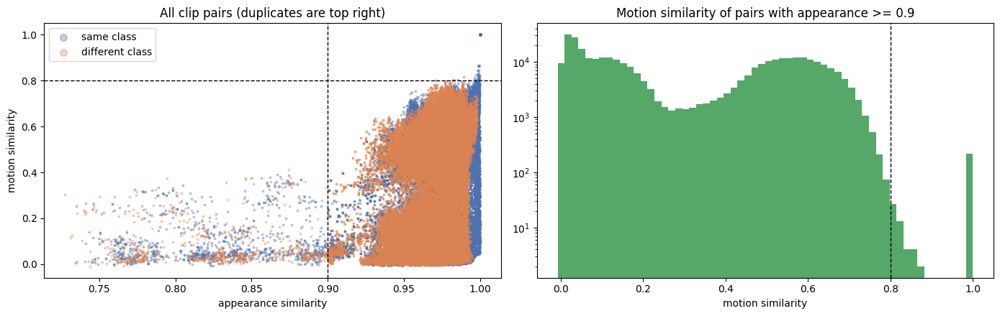

In [10]:
APP_THR = 0.90
MOT_THR = 0.80

plot_df = pd.concat([
    pairs_df.sample(min(len(pairs_df), 40000), random_state=SEED),
    pairs_df[pairs_df['app'] >= 0.9],
]).drop_duplicates()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for cross, color, name in [(False, '#4C72B0', 'same class'), (True, '#DD8452', 'different class')]:
    part = plot_df[plot_df['cross'] == cross]
    axes[0].scatter(part['app'], part['mot'], s=3, alpha=0.35, color=color, label=name)
axes[0].axvline(APP_THR, color='k', ls='--', lw=1)
axes[0].axhline(MOT_THR, color='k', ls='--', lw=1)
axes[0].set_xlabel('appearance similarity')
axes[0].set_ylabel('motion similarity')
axes[0].set_title('All clip pairs (duplicates are top right)')
axes[0].legend(markerscale=4)
same_cam = pairs_df[pairs_df['app'] >= APP_THR]
axes[1].hist(same_cam['mot'], bins=60, color='#55A868')
axes[1].axvline(MOT_THR, color='k', ls='--', lw=1)
axes[1].set_yscale('log')
axes[1].set_xlabel('motion similarity')
axes[1].set_title(f'Motion similarity of pairs with appearance >= {APP_THR}')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/duplicate_similarity.png', dpi=120, bbox_inches='tight')
plt.show()

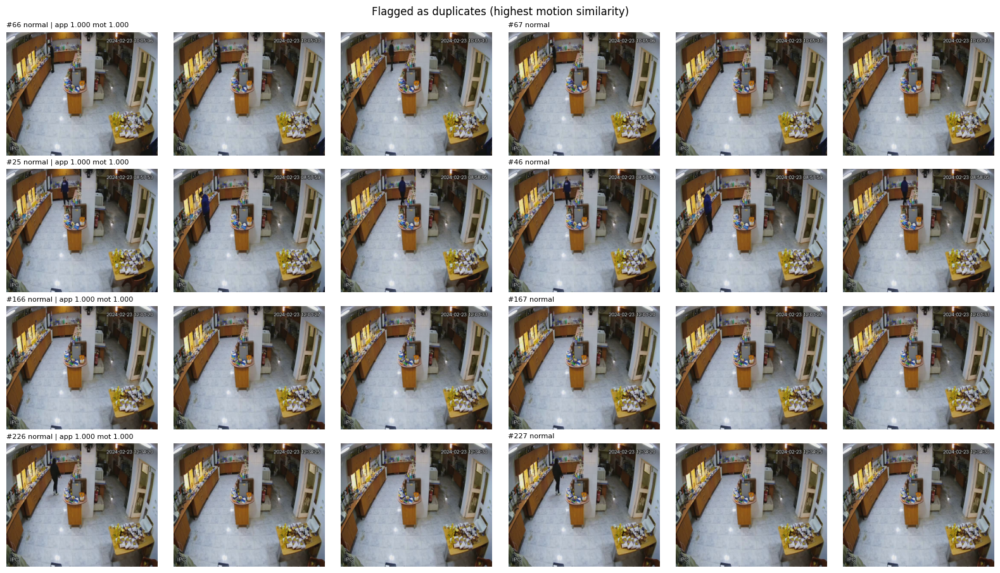

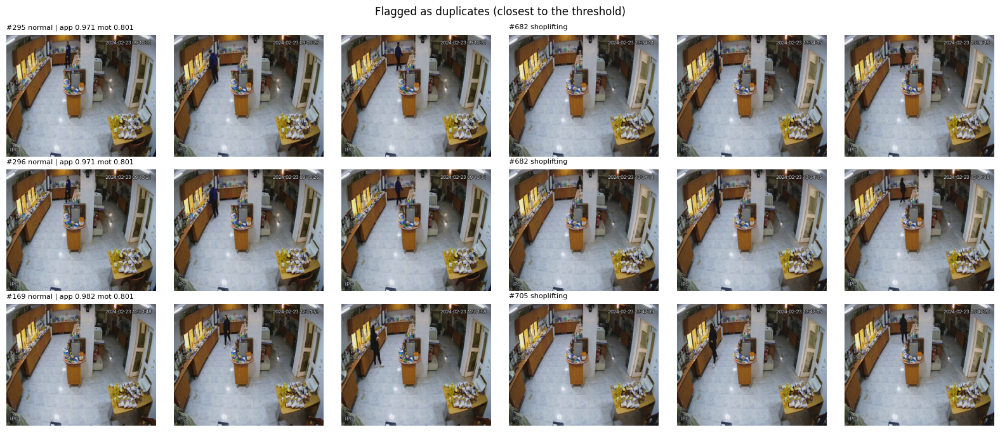

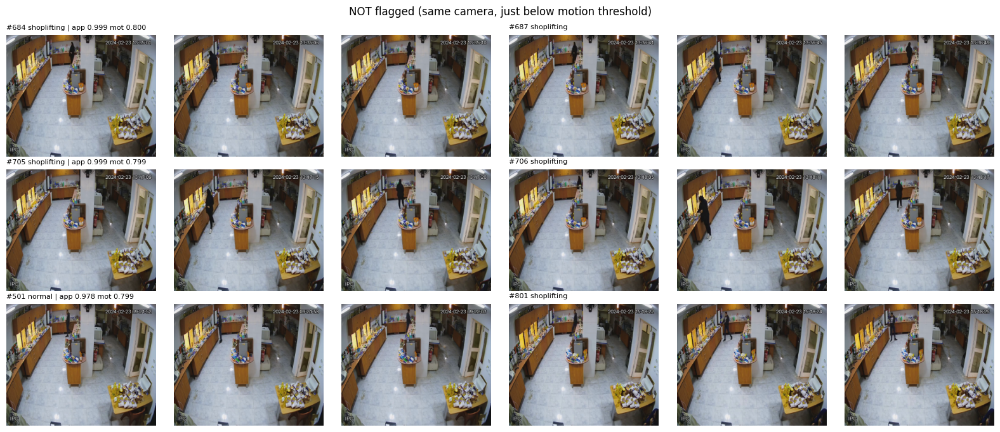

In [11]:
def show_pairs(pair_rows, title, fname):
    if len(pair_rows) == 0:
        print('no pairs to show for:', title)
        return
    cols = [8, 32, 56]
    fig, axes = plt.subplots(len(pair_rows), 6, figsize=(16, 2.3 * len(pair_rows)), squeeze=False)
    for r, (_, pr) in enumerate(pair_rows.iterrows()):
        for side, cid in enumerate([int(pr['i']), int(pr['j'])]):
            arr = np.load(cache_path_for(cid), mmap_mode='r')
            for c, f in enumerate(cols):
                ax = axes[r, side * 3 + c]
                ax.imshow(arr[f])
                ax.axis('off')
                if c == 0:
                    extra = f" | app {pr['app']:.3f} mot {pr['mot']:.3f}" if side == 0 else ''
                    ax.set_title(f"#{cid} {IDX_TO_NAME[df.loc[cid, 'label']]}{extra}", fontsize=8, loc='left')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{fname}', dpi=100, bbox_inches='tight')
    plt.show()

near = pairs_df[(pairs_df['app'] >= APP_THR) & (pairs_df['mot'] >= MOT_THR)]
show_pairs(near.sort_values('mot', ascending=False).head(4), 'Flagged as duplicates (highest motion similarity)', 'dup_top.png')
show_pairs(near.sort_values('mot').head(3), 'Flagged as duplicates (closest to the threshold)', 'dup_border.png')
below = pairs_df[(pairs_df['app'] >= APP_THR) & (pairs_df['mot'] < MOT_THR)]
show_pairs(below.sort_values('mot', ascending=False).head(3), 'NOT flagged (same camera, just below motion threshold)', 'dup_below.png')

- Top rows should be the same people doing the same thing (real duplicates)
- The last figure should look like the same camera but different people or actions
- If the border cases look wrong, change `MOT_THR` in the cell above and run again

### 5.4 Duplicate groups and cleaning

- Duplicate pairs = exact MD5 pairs + near duplicate pairs
- Clips connected by duplicate pairs form a **group** (union find). A group always stays in one split
- Cross-class duplicates: same footage with two labels, so I drop all of those clips
- Exact copies within the same class: I keep only one copy

In [12]:
md5_pairs = []
for _, ids in df.groupby('md5')['clip_id']:
    ids = sorted(ids)
    md5_pairs += [(a, b) for k, a in enumerate(ids) for b in ids[k + 1:]]
md5_df = pd.DataFrame(md5_pairs, columns=['i', 'j'])
md5_df = md5_df.merge(pairs_df, on=['i', 'j'], how='left')
md5_df['exact'] = True

near_df = near.copy()
near_df['exact'] = False
dup_df = pd.concat([md5_df, near_df]).sort_values('exact', ascending=False)
dup_df = dup_df.drop_duplicates(['i', 'j']).reset_index(drop=True)
dup_df['cross'] = df['label'].values[dup_df['i']] != df['label'].values[dup_df['j']]
dup_df['path_i'] = df['path'].values[dup_df['i']]
dup_df['path_j'] = df['path'].values[dup_df['j']]
dup_df.to_csv(f'{SAVE_DIR}/duplicate_pairs.csv', index=False)


def build_groups(ids, pairs):
    parent = {i: i for i in ids}

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in pairs:
        if a in parent and b in parent:
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[rb] = ra
    return {i: find(i) for i in ids}


conflict_ids = set(dup_df.loc[dup_df['cross'], 'i']) | set(dup_df.loc[dup_df['cross'], 'j'])
exact_extra = set(df.index[df.duplicated('md5', keep='first')]) - conflict_ids
remove_ids = conflict_ids | exact_extra

clean_df = df.drop(index=sorted(remove_ids)).copy()
groups = build_groups(clean_df.index.tolist(), zip(dup_df['i'], dup_df['j']))
clean_df['group'] = clean_df.index.map(groups)
group_sizes = clean_df['group'].value_counts()

dup_summary = pd.Series({
    'clips before': len(df),
    'exact duplicate pairs': int(dup_df['exact'].sum()),
    'exact pairs across classes': int((dup_df['exact'] & dup_df['cross']).sum()),
    'near duplicate pairs': int((~dup_df['exact']).sum()),
    'near pairs across classes': int((~dup_df['exact'] & dup_df['cross']).sum()),
    'removed (label conflict)': len(conflict_ids),
    'removed (extra exact copies)': len(exact_extra),
    'clips after': len(clean_df),
    'groups': clean_df['group'].nunique(),
    'groups with 2+ clips': int((group_sizes > 1).sum()),
    'largest group': int(group_sizes.max()),
})
print(dup_summary.to_string())
print()
print(clean_df['class'].value_counts())
if group_sizes.max() > 0.1 * len(clean_df):
    print('WARNING: one group holds more than 10% of the data, check MOT_THR')

clips before                    855
exact duplicate pairs           218
exact pairs across classes        0
near duplicate pairs             46
near pairs across classes         8
removed (label conflict)          9
removed (extra exact copies)    215
clips after                     631
groups                          606
groups with 2+ clips             14
largest group                     6

class
shop lifters        321
non shop lifters    310
Name: count, dtype: int64


### 5.5 How much did the Week 5 split leak?

- I rebuild the exact Week 5 split (same `random_state=42`) and count test clips that had a duplicate in train

In [13]:
old_train, old_temp = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
old_val, old_test = train_test_split(old_temp, test_size=0.50, stratify=old_temp['label'], random_state=42)

partners = {}
for a, b in zip(dup_df['i'], dup_df['j']):
    partners.setdefault(a, set()).add(b)
    partners.setdefault(b, set()).add(a)

old_train_ids = set(old_train.index)
leaked = [c for c in old_test.index if partners.get(c, set()) & old_train_ids]
conflict_in_test = [c for c in old_test.index if c in conflict_ids]
print(f'week 5 test clips with a duplicate in week 5 train: {len(leaked)} / {len(old_test)} ({len(leaked) / len(old_test):.1%})')
print(f'week 5 test clips with a label conflict: {len(conflict_in_test)}')

week 5 test clips with a duplicate in week 5 train: 52 / 129 (40.3%)
week 5 test clips with a label conflict: 2


- Any number above 0 means the Week 5 test F1 (0.9247) was partly measured on clips the model had already seen
- That is why I retrain the scratch model on the clean split in section 9 for a fair comparison

## 6. Leak free split

- `StratifiedGroupKFold` keeps class balance and never puts one group in two splits
- About 72% train, 14% val, 14% test
- The split is saved to `split.csv` so both models use the exact same clips

In [14]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_idx, test_idx = next(sgkf.split(clean_df, clean_df['label'], clean_df['group']))
trval = clean_df.iloc[trval_idx]
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf2.split(trval, trval['label'], trval['group']))

clean_df['split'] = 'test'
clean_df.loc[trval.index[tr_idx], 'split'] = 'train'
clean_df.loc[trval.index[va_idx], 'split'] = 'val'

split_groups = {s: set(clean_df.loc[clean_df['split'] == s, 'group']) for s in ['train', 'val', 'test']}
assert not split_groups['train'] & split_groups['val']
assert not split_groups['train'] & split_groups['test']
assert not split_groups['val'] & split_groups['test']

split_of = clean_df['split'].to_dict()
kept = dup_df[dup_df['i'].isin(split_of) & dup_df['j'].isin(split_of)]
crossing = [(a, b) for a, b in zip(kept['i'], kept['j']) if split_of[a] != split_of[b]]
assert len(crossing) == 0
print('no duplicate pair crosses splits')

tr_ids = clean_df.index[clean_df['split'] == 'train'].to_numpy()
te_ids = clean_df.index[clean_df['split'] == 'test'].to_numpy()
both = (app_sim[np.ix_(te_ids, tr_ids)] >= APP_THR)
closest = (mot_sim[np.ix_(te_ids, tr_ids)] * both).max()
print(f'highest motion similarity between a test clip and a train clip (same camera): {closest:.3f} (threshold {MOT_THR})')

split_table = pd.crosstab(clean_df['class'], clean_df['split'])[['train', 'val', 'test']]
split_table.loc['total'] = split_table.sum()
print(split_table)
clean_df[['clip_id', 'path', 'class', 'label', 'frames', 'duration', 'md5', 'group', 'split']].to_csv(f'{SAVE_DIR}/split.csv', index=False)

train_df = clean_df[clean_df['split'] == 'train'].reset_index(drop=True)
val_df = clean_df[clean_df['split'] == 'val'].reset_index(drop=True)
test_df = clean_df[clean_df['split'] == 'test'].reset_index(drop=True)

counts = train_df['label'].value_counts().sort_index().values
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32)
print('class weights:', [round(w, 3) for w in class_weights.tolist()])

no duplicate pair crosses splits
highest motion similarity between a test clip and a train clip (same camera): 0.800 (threshold 0.8)
split             train  val  test
class                             
non shop lifters    222   43    45
shop lifters        228   44    49
total               450   87    94
class weights: [1.014, 0.987]


## 7. Augmentation and datasets (from Week 5)

- `augment_clip` is my Week 5 function. I only added `resize`, `crop`, `mean`, `std` as arguments so both models can use it
  - scratch model: resize 160x196, crop 144x176, values in [0, 1] (same as Week 5)
  - VideoMAE: resize 240x240, crop 224x224, then ImageNet mean/std from the VideoMAE processor
- Same random crop, flip and color jitter for **all** frames of a clip (checked below, like Week 5)
- Training also picks a random temporal view, which is a free temporal augmentation

In [15]:
def augment_clip(clip, train=True, resize=SCRATCH_RESIZE, crop=SCRATCH_CROP, mean=None, std=None):
    x = torch.from_numpy(np.ascontiguousarray(clip)).permute(0, 3, 1, 2).float() / 255.0
    x = F.interpolate(x, size=resize, mode='bilinear', align_corners=False, antialias=True)
    rh, rw = resize
    ch, cw = crop
    if train:
        top = random.randint(0, rh - ch)
        left = random.randint(0, rw - cw)
        flip = random.random() < 0.5
        brightness = random.uniform(0.7, 1.3)
        contrast = random.uniform(0.7, 1.3)
        saturation = random.uniform(0.7, 1.3)
    else:
        top = (rh - ch) // 2
        left = (rw - cw) // 2
        flip = False
        brightness = contrast = saturation = 1.0
    x = x[:, :, top:top + ch, left:left + cw]
    if flip:
        x = torch.flip(x, dims=[3])
    x = (x * brightness).clamp(0, 1)
    m = x.mean()
    x = ((x - m) * contrast + m).clamp(0, 1)
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = ((x - gray) * saturation + gray).clamp(0, 1)
    if mean is not None:
        x = (x - torch.tensor(mean).view(1, 3, 1, 1)) / torch.tensor(std).view(1, 3, 1, 1)
    params = dict(top=top, left=left, flip=flip, brightness=round(brightness, 3),
                  contrast=round(contrast, 3), saturation=round(saturation, 3))
    return x, params


scratch_aug = dict(resize=SCRATCH_RESIZE, crop=SCRATCH_CROP)
vm_aug = dict(resize=VM_RESIZE, crop=VM_CROP, mean=VM_MEAN, std=VM_STD)

arr = np.load(cache_path_for(int(train_df['clip_id'].iloc[0])))
same_clip = np.stack([arr[0]] * VM_FRAMES)
for name, aug in [('scratch', scratch_aug), ('videomae', vm_aug)]:
    for seed in range(30):
        random.seed(seed)
        out, p = augment_clip(same_clip, train=True, **aug)
        assert out.shape == (VM_FRAMES, 3, *aug['crop'])
        assert torch.allclose(out, out[0:1].expand_as(out))
    print(f'{name}: 30 random augmentations, all frames got the same transform')

scratch: 30 random augmentations, all frames got the same transform
videomae: 30 random augmentations, all frames got the same transform


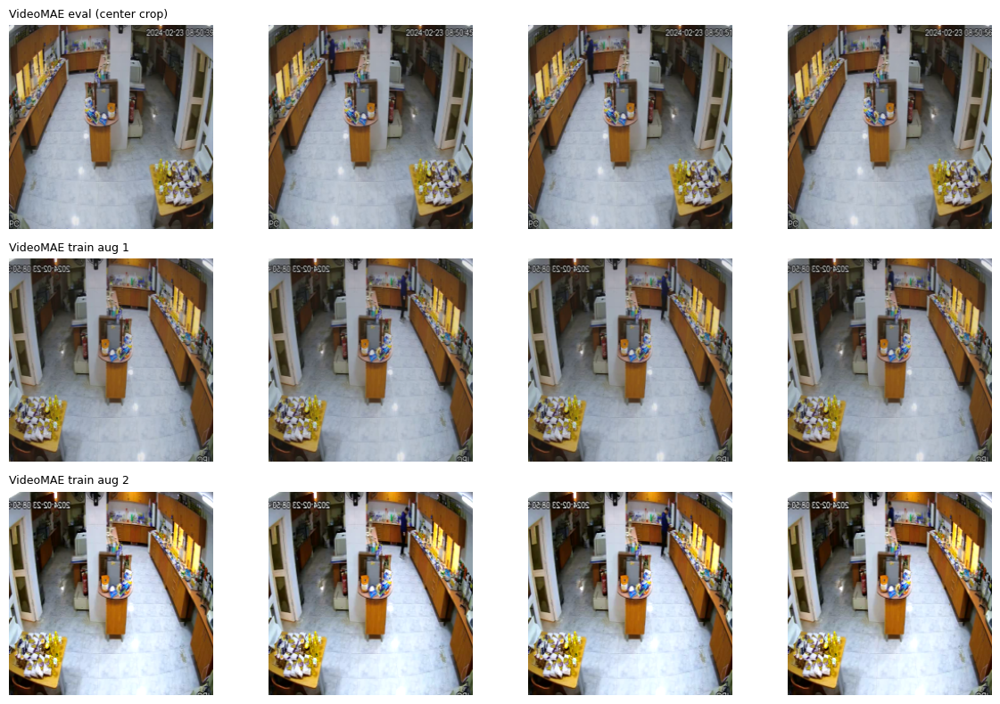

In [16]:
def denorm(x):
    return (x * torch.tensor(VM_STD).view(3, 1, 1) + torch.tensor(VM_MEAN).view(3, 1, 1)).clamp(0, 1)

clip = arr[vm_sets[CENTER_VIEW]]
demo = [('VideoMAE eval (center crop)', augment_clip(clip, train=False, **vm_aug)[0])]
for seed in [1, 2]:
    random.seed(seed)
    demo.append((f'VideoMAE train aug {seed}', augment_clip(clip, train=True, **vm_aug)[0]))
show = [0, 5, 10, 15]
fig, axes = plt.subplots(len(demo), len(show), figsize=(12, 8))
for r, (name, x) in enumerate(demo):
    for c, f in enumerate(show):
        axes[r, c].imshow(denorm(x[f]).permute(1, 2, 0).numpy())
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_title(name, fontsize=9, loc='left')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/videomae_augmentation.png', dpi=100, bbox_inches='tight')
plt.show()

In [17]:
class ShopliftingDataset(Dataset):
    def __init__(self, frame_df, index_sets, train, resize, crop, mean=None, std=None, eval_views=None):
        self.df = frame_df.reset_index(drop=True)
        self.index_sets = [np.asarray(s) for s in index_sets]
        self.train = train
        self.aug = dict(resize=resize, crop=crop, mean=mean, std=std)
        self.eval_views = eval_views if eval_views is not None else [0]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        arr = np.load(cache_path_for(int(row['clip_id'])), mmap_mode='r')
        y = torch.tensor(int(row['label']), dtype=torch.long)
        if self.train:
            idx = self.index_sets[random.randrange(len(self.index_sets))]
            x, _ = augment_clip(arr[idx], train=True, **self.aug)
            return x, y
        views = [augment_clip(arr[self.index_sets[v]], train=False, **self.aug)[0] for v in self.eval_views]
        x = views[0] if len(views) == 1 else torch.stack(views)
        return x, y


def make_loader(ds, batch_size, shuffle):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda',
                      persistent_workers=NUM_WORKERS > 0)


checks = [
    ('scratch T=16', ShopliftingDataset(val_df, [get_frame_indices(N_CACHE, 16)], False, **scratch_aug), (16, 3, *SCRATCH_CROP)),
    ('videomae train', ShopliftingDataset(train_df, vm_sets, True, **vm_aug), (VM_FRAMES, 3, *VM_CROP)),
    ('videomae 1 view', ShopliftingDataset(val_df, vm_sets, False, eval_views=[CENTER_VIEW], **vm_aug), (VM_FRAMES, 3, *VM_CROP)),
    ('videomae 4 views', ShopliftingDataset(val_df, vm_sets, False, eval_views=list(range(N_VIEWS)), **vm_aug), (N_VIEWS, VM_FRAMES, 3, *VM_CROP)),
]
for name, ds, shape in checks:
    for i in tqdm(random.sample(range(len(ds)), min(16, len(ds))), desc=name, leave=False):
        x, y = ds[i]
        assert tuple(x.shape) == shape and x.dtype == torch.float32, (name, x.shape)
    print(f'{name}: ok, shape {shape}')

scratch T=16:   0%|          | 0/16 [00:00<?, ?it/s]

scratch T=16: ok, shape (16, 3, 144, 176)


videomae train:   0%|          | 0/16 [00:00<?, ?it/s]

videomae train: ok, shape (16, 3, 224, 224)


videomae 1 view:   0%|          | 0/16 [00:00<?, ?it/s]

videomae 1 view: ok, shape (16, 3, 224, 224)


videomae 4 views:   0%|          | 0/16 [00:00<?, ?it/s]

videomae 4 views: ok, shape (4, 16, 3, 224, 224)


## 8. Training and evaluation helpers

- Same recipe as Week 5: AdamW, cosine LR, class weights, label smoothing 0.1, grad clipping, mixed precision, early stopping on val F1
- New things for the big model: warmup, gradient accumulation and a separate LR for the new head
- The scheduler now steps every optimizer step (almost the same curve as the Week 5 per-epoch cosine)
- Multi-view evaluation averages the softmax over the 4 views

In [18]:
def predict(model, loader, amp_dtype):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for x, y in tqdm(loader, desc='predict', leave=False):
            x = x.to(device, non_blocking=True)
            multi = x.dim() == 6
            if multi:
                b, v = x.shape[:2]
                x = x.flatten(0, 1)
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=device.type == 'cuda'):
                logits = model(x)
            p = logits.float().softmax(1)
            if multi:
                p = p.view(b, v, -1).mean(1)
            probs.append(p.cpu())
            labels.append(y)
    return torch.cat(probs), torch.cat(labels)


def compute_metrics(probs, labels):
    preds = probs.argmax(1).numpy()
    y = labels.numpy()
    p, r, f1, _ = precision_recall_fscore_support(y, preds, average='binary', pos_label=1, zero_division=0)
    loss = F.nll_loss(torch.log(probs.clamp_min(1e-8)), labels, weight=class_weights).item()
    auc = roc_auc_score(y, probs[:, 1].numpy()) if len(np.unique(y)) > 1 else float('nan')
    return dict(loss=loss, acc=accuracy_score(y, preds), precision=p, recall=r, f1=f1,
                macro_f1=f1_score(y, preds, average='macro', zero_division=0), auc=auc,
                probs=probs.numpy(), preds=preds, labels=y)


def make_param_groups(model, lr, weight_decay, head_keyword=None, head_lr=None):
    buckets = {}
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        is_head = head_keyword is not None and head_keyword in name
        buckets.setdefault((is_head, p.ndim > 1), []).append(p)
    return [{'params': ps, 'lr': head_lr if is_head else lr, 'weight_decay': weight_decay if decay else 0.0}
            for (is_head, decay), ps in buckets.items()]


def train_model(model, train_loader, val_loader, param_groups, epochs, patience, amp_dtype,
                accum=1, warmup_epochs=0, label_smoothing=0.1, grad_clip=1.0, tag=''):
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(param_groups)
    steps_per_epoch = math.ceil(len(train_loader) / accum)
    total = epochs * steps_per_epoch
    warm = warmup_epochs * steps_per_epoch

    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(1, total - warm)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    use_amp = device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp and amp_dtype == torch.float16)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    best_f1, best_loss, best_epoch, best_state, best_val, bad = -1.0, float('inf'), 0, None, None, 0
    epoch_times = []

    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        running, seen = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        pbar = tqdm(train_loader, desc=f'{tag} epoch {epoch}/{epochs}', leave=False)
        for step, (x, y) in enumerate(pbar):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss / accum).backward()
            if (step + 1) % accum == 0 or step + 1 == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
            running += loss.item() * len(y)
            seen += len(y)
            pbar.set_postfix(loss=f'{running / seen:.4f}')
        epoch_times.append(time.time() - t0)

        val = compute_metrics(*predict(model, val_loader, amp_dtype))
        history['train_loss'].append(running / seen)
        history['val_loss'].append(val['loss'])
        history['val_acc'].append(val['acc'])
        history['val_f1'].append(val['f1'])
        improved = val['f1'] > best_f1 or (val['f1'] == best_f1 and val['loss'] < best_loss)
        if improved:
            best_f1, best_loss, best_epoch, best_val, bad = val['f1'], val['loss'], epoch, val, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f"{tag} epoch {epoch:2d} | train loss {running / seen:.4f} | val loss {val['loss']:.4f} | "
              f"acc {val['acc']:.4f} | prec {val['precision']:.3f} | rec {val['recall']:.3f} | "
              f"f1 {val['f1']:.4f} | {epoch_times[-1]:.0f}s{' *' if improved else ''}")
        if bad >= patience:
            print(f'{tag} early stopping at epoch {epoch}')
            break

    model.load_state_dict(best_state)
    print(f'{tag} best val f1 {best_f1:.4f} at epoch {best_epoch}')
    return model, history, dict(best_epoch=best_epoch, best_val=best_val, sec_per_epoch=float(np.mean(epoch_times)))


def sync(dev):
    if dev.type == 'cuda':
        torch.cuda.synchronize()


def time_inference(model, input_shape, dev, amp_dtype=None, runs=30, warmup=5):
    model = model.to(dev).eval()
    x = torch.randn(input_shape, device=dev)
    ctx = torch.autocast(device_type=dev.type, dtype=amp_dtype) if amp_dtype is not None else nullcontext()
    with torch.no_grad(), ctx:
        for _ in range(warmup):
            model(x)
        sync(dev)
        t0 = time.perf_counter()
        for _ in range(runs):
            model(x)
        sync(dev)
    return (time.perf_counter() - t0) / runs * 1000


def plot_history(history, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(history['train_loss'], label='train (smoothed)')
    axes[0].plot(history['val_loss'], label='val')
    axes[0].set_title(f'{title}: loss')
    axes[0].set_xlabel('epoch')
    axes[0].legend()
    axes[1].plot(history['val_acc'], label='val accuracy')
    axes[1].plot(history['val_f1'], label='val F1')
    axes[1].set_title(f'{title}: validation')
    axes[1].set_xlabel('epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{fname}', dpi=110, bbox_inches='tight')
    plt.show()


def free_memory():
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

## 9. Scratch model: T analysis and retrain

### 9.1 Week 5 model (same architecture)

- Residual CNN frame encoder + BiLSTM, about 1.6M parameters

In [19]:
class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.relu = nn.ReLU(inplace=True)
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(
                nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                nn.BatchNorm2d(c_out),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))


class ResFrameEncoder(nn.Module):
    def __init__(self, widths=(32, 64, 128, 256)):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True),
        )
        self.stages = nn.Sequential(
            ResBlock(widths[0], widths[0], 1),
            ResBlock(widths[0], widths[1], 2),
            ResBlock(widths[1], widths[2], 2),
            ResBlock(widths[2], widths[3], 2),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = widths[3]

    def forward(self, x):
        return self.pool(self.stages(self.stem(x))).flatten(1)


class ResCNNLSTM(nn.Module):
    def __init__(self, hidden=128, num_classes=2):
        super().__init__()
        self.encoder = ResFrameEncoder()
        self.feat_drop = nn.Dropout(0.3)
        self.lstm = nn.LSTM(self.encoder.out_dim, hidden, num_layers=1, batch_first=True, bidirectional=True)
        self.cls_drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 4, num_classes)
        for m in self.encoder.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        b, t, c, h, w = x.shape
        f = self.encoder(x.reshape(b * t, c, h, w)).reshape(b, t, -1)
        f = self.feat_drop(f)
        seq, _ = self.lstm(f)
        pooled = torch.cat([seq.mean(dim=1), seq.max(dim=1).values], dim=1)
        return self.fc(self.cls_drop(pooled))

print(f'parameters: {sum(p.numel() for p in ResCNNLSTM().parameters()):,}')

parameters: 1,622,690


### 9.2 How many frames? (T analysis)

- Mentor feedback: no reason was given for T = 16 and it may miss parts of the video
- I train the same model with T = 8, 16, 32, 48 on the clean split and compare **val** F1 (test is not touched)
- Shorter runs (25 epochs) to keep it fast, same settings for every T
- I also measure the inference time per clip, since more frames cost more compute

In [20]:
SCRATCH_CONFIG = dict(epochs=70, patience=20, batch_size=8, lr=1e-3, weight_decay=5e-2, label_smoothing=0.1, grad_clip=1.0)
ABL_EPOCHS, ABL_PATIENCE = 25, 10
median_dur = clean_df['duration'].median()

ablation_rows = []
for T in tqdm(T_CANDIDATES, desc='T analysis'):
    seed_everything(SEED)
    sets = [get_frame_indices(N_CACHE, T)]
    tr = make_loader(ShopliftingDataset(train_df, sets, True, **scratch_aug), SCRATCH_CONFIG['batch_size'], True)
    va = make_loader(ShopliftingDataset(val_df, sets, False, **scratch_aug), 16, False)
    m = ResCNNLSTM().to(device)
    groups_ = make_param_groups(m, SCRATCH_CONFIG['lr'], SCRATCH_CONFIG['weight_decay'])
    m, _, info = train_model(m, tr, va, groups_, ABL_EPOCHS, ABL_PATIENCE, SCRATCH_AMP, tag=f'T={T}')
    ms = time_inference(m, (1, T, 3, *SCRATCH_CROP), device)
    ablation_rows.append(dict(T=T, gap_seconds=round(median_dur / T, 2), val_f1=info['best_val']['f1'],
                              val_acc=info['best_val']['acc'], val_loss=info['best_val']['loss'],
                              best_epoch=info['best_epoch'], sec_per_epoch=info['sec_per_epoch'], ms_per_clip=ms))
    del m, tr, va
    free_memory()

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(f'{SAVE_DIR}/t_ablation.csv', index=False)
BEST_T = int(ablation_df.sort_values(['val_f1', 'val_loss', 'T'], ascending=[False, True, True]).iloc[0]['T'])
print(ablation_df.round(4).to_string(index=False))
print('best T on validation:', BEST_T)

T analysis:   0%|          | 0/4 [00:00<?, ?it/s]

T=8 epoch 1/25:   0%|          | 0/56 [00:00<?, ?it/s]

predict:   0%|          | 0/6 [00:00<?, ?it/s]

T=8 epoch  1 | train loss 0.7208 | val loss 0.6921 | acc 0.5057 | prec 0.506 | rec 1.000 | f1 0.6718 | 20s *


T=8 epoch 2/25:   0%|          | 0/56 [00:00<?, ?it/s]

...

predict:   0%|          | 0/6 [00:00<?, ?it/s]

T=48 epoch 24 | train loss 0.5457 | val loss 0.3877 | acc 0.8621 | prec 0.864 | rec 0.864 | f1 0.8636 | 93s


T=48 epoch 25/25:   0%|          | 0/56 [00:00<?, ?it/s]

predict:   0%|          | 0/6 [00:00<?, ?it/s]

T=48 epoch 25 | train loss 0.5230 | val loss 0.3820 | acc 0.8621 | prec 0.848 | rec 0.886 | f1 0.8667 | 91s
T=48 best val f1 0.8706 at epoch 22
 T  gap_seconds  val_f1  val_acc  val_loss  best_epoch  sec_per_epoch  ms_per_clip
 8         1.62  0.8966   0.8966    0.3941          19        11.4574       4.3026
16         0.81  0.8941   0.8966    0.4199          20        31.8955       6.1061
32         0.41  0.9070   0.9080    0.3672          22        61.0484      11.6861
48         0.27  0.8706   0.8736    0.3815          22        91.9619      17.3607
best T on validation: 32


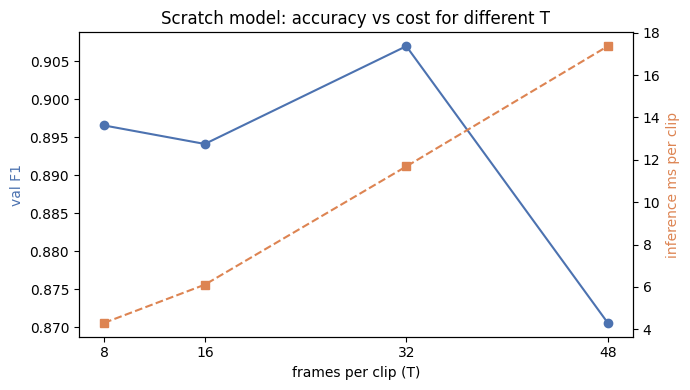

In [21]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(ablation_df['T'], ablation_df['val_f1'], 'o-', color='#4C72B0', label='val F1')
ax1.set_xlabel('frames per clip (T)')
ax1.set_ylabel('val F1', color='#4C72B0')
ax1.set_xticks(T_CANDIDATES)
ax2 = ax1.twinx()
ax2.plot(ablation_df['T'], ablation_df['ms_per_clip'], 's--', color='#DD8452', label='ms per clip')
ax2.set_ylabel('inference ms per clip', color='#DD8452')
plt.title('Scratch model: accuracy vs cost for different T')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/t_ablation.png', dpi=120, bbox_inches='tight')
plt.show()

- `gap_seconds` is the time between two sampled frames for a median length video
- With T = 8 or 16 the gap is around 1 second or more, so a fast grab can fall between two frames
- More frames usually help until the LSTM starts overfitting on so few videos, and the cost grows linearly with T
- I keep the T with the best val F1 (`BEST_T`) for the final scratch model

### 9.3 Final scratch model on the clean split

- Same Week 5 config (70 epochs, patience 20) with `BEST_T`
- This is the fair baseline for the comparison because it uses the same clean split as VideoMAE

scratch epoch 1/70:   0%|          | 0/56 [00:00<?, ?it/s]

predict:   0%|          | 0/6 [00:00<?, ?it/s]

scratch epoch  1 | train loss 0.7303 | val loss 0.7058 | acc 0.5057 | prec 0.506 | rec 1.000 | f1 0.6718 | 57s *


scratch epoch 2/70:   0%|          | 0/56 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795f7396fce0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795f7396fce0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

predict:   0%|          | 0/6 [00:00<?, ?it/s]

scratch epoch 69 | train loss 0.2506 | val loss 0.0992 | acc 0.9655 | prec 0.936 | rec 1.000 | f1 0.9670 | 54s


scratch epoch 70/70:   0%|          | 0/56 [00:00<?, ?it/s]

predict:   0%|          | 0/6 [00:00<?, ?it/s]

scratch epoch 70 | train loss 0.2530 | val loss 0.0810 | acc 0.9885 | prec 0.978 | rec 1.000 | f1 0.9888 | 54s *
scratch best val f1 0.9888 at epoch 70


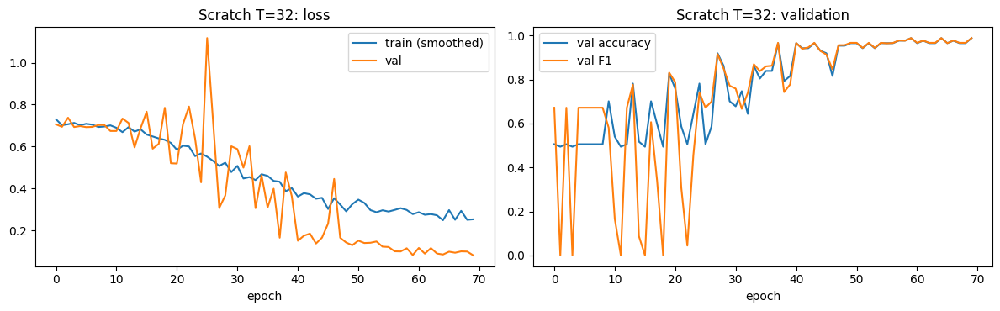

predict:   0%|          | 0/6 [00:00<?, ?it/s]

scratch test | acc 0.9894 | prec 0.9800 | rec 1.0000 | f1 0.9899


In [29]:
seed_everything(SEED)
scratch_sets = [get_frame_indices(N_CACHE, BEST_T)]
sc_train_loader = make_loader(ShopliftingDataset(train_df, scratch_sets, True, **scratch_aug), SCRATCH_CONFIG['batch_size'], True)
sc_val_loader = make_loader(ShopliftingDataset(val_df, scratch_sets, False, **scratch_aug), 16, False)
sc_test_loader = make_loader(ShopliftingDataset(test_df, scratch_sets, False, **scratch_aug), 16, False)

scratch_model = ResCNNLSTM().to(device)
scratch_model, scratch_hist, scratch_info = train_model(
    scratch_model, sc_train_loader, sc_val_loader,
    make_param_groups(scratch_model, SCRATCH_CONFIG['lr'], SCRATCH_CONFIG['weight_decay']),
    SCRATCH_CONFIG['epochs'], SCRATCH_CONFIG['patience'], SCRATCH_AMP,
    label_smoothing=SCRATCH_CONFIG['label_smoothing'], grad_clip=SCRATCH_CONFIG['grad_clip'], tag='scratch')
SCRATCH_PATH = f'{SAVE_DIR}/scratch_res_cnn_lstm_T{BEST_T}.pt'
torch.save(scratch_model.state_dict(), SCRATCH_PATH)
plot_history(scratch_hist, f'Scratch T={BEST_T}', 'scratch_history.png')

scratch_test = compute_metrics(*predict(scratch_model, sc_test_loader, SCRATCH_AMP))
print(f"scratch test | acc {scratch_test['acc']:.4f} | prec {scratch_test['precision']:.4f} | "
      f"rec {scratch_test['recall']:.4f} | f1 {scratch_test['f1']:.4f}")


## 10. Pretrained VideoMAE: load and adapt the head

- `id2label` / `label2id` with 2 classes makes the config `num_labels = 2`
- `ignore_mismatched_sizes=True` keeps all pretrained weights and only re-creates the classifier (400 Kinetics classes to 2)
- `output_loading_info=True` lets me prove that nothing else was missing or broken

In [24]:
hf_model, load_info = VideoMAEForVideoClassification.from_pretrained(
    MODEL_ID,
    id2label=IDX_TO_NAME,
    label2id={v: k for k, v in IDX_TO_NAME.items()},
    ignore_mismatched_sizes=True,
    output_loading_info=True,
)

print('missing keys   :', sorted(load_info['missing_keys']))
print('unexpected keys:', sorted(load_info['unexpected_keys']))
print('mismatched keys:', [(k, tuple(a), tuple(b)) for k, a, b in load_info['mismatched_keys']])
print('errors         :', load_info['error_msgs'])

assert len(load_info['error_msgs']) == 0
assert all(k.startswith('classifier') for k in load_info['missing_keys'])
assert all(k[0].startswith('classifier') for k in load_info['mismatched_keys'])
assert hf_model.classifier.out_features == 2 and hf_model.config.num_labels == 2
print()
print('loaded without errors, only the classifier head was replaced')
print('new head:', hf_model.classifier)
print('frames:', hf_model.config.num_frames, '| image size:', hf_model.config.image_size,
      '| tubelet:', hf_model.config.tubelet_size, '| hidden:', hf_model.config.hidden_size)
print(f'parameters: {sum(p.numel() for p in hf_model.parameters()):,}')

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


missing keys   : []
unexpected keys: []
mismatched keys: [('classifier.bias', (400,), (2,)), ('classifier.weight', (400, 768), (2, 768))]
errors         : []

loaded without errors, only the classifier head was replaced
new head: Linear(in_features=768, out_features=2, bias=True)
frames: 16 | image size: 224 | tubelet: 2 | hidden: 768
parameters: 86,228,738


In [25]:
class VideoMAEClassifier(nn.Module):
    def __init__(self, hf):
        super().__init__()
        self.m = hf

    def forward(self, x):
        return self.m(pixel_values=x).logits


if VM_CKPT:
    hf_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
vm_model = VideoMAEClassifier(hf_model).to(device)

vm_train_loader = make_loader(ShopliftingDataset(train_df, vm_sets, True, **vm_aug), VM_BATCH, True)
vm_val_loader = make_loader(ShopliftingDataset(val_df, vm_sets, False, eval_views=[CENTER_VIEW], **vm_aug), VM_BATCH * 2, False)

xb, yb = next(iter(vm_train_loader))
vm_model.eval()
with torch.no_grad(), torch.autocast(device_type=device.type, dtype=VM_AMP, enabled=device.type == 'cuda'):
    out = vm_model(xb.to(device))
print('input:', tuple(xb.shape), '-> logits:', tuple(out.shape))
assert out.shape == (xb.shape[0], 2)

input: (4, 16, 3, 224, 224) -> logits: (4, 2)


## 11. Fine-tuning VideoMAE

- Whole model is fine-tuned, but the pretrained backbone gets a small LR (3e-5) and the new head a bigger one (5e-4)
- 1 warmup epoch so the random head does not damage the pretrained features at the start
- Same loss as the scratch model (class weights + label smoothing 0.1)
- Validation uses the center view only (fast). Multi-view is tested in section 12

videomae epoch 1/70:   0%|          | 0/112 [00:00<?, ?it/s]

predict:   0%|          | 0/11 [00:00<?, ?it/s]

videomae epoch  1 | train loss 0.6402 | val loss 0.6295 | acc 0.6322 | prec 0.581 | rec 0.977 | f1 0.7288 | 63s *


videomae epoch 2/70:   0%|          | 0/112 [00:00<?, ?it/s]

predict:   0%|          | 0/11 [00:00<?, ?it/s]

...

videomae epoch 49 | train loss 0.1988 | val loss 0.0551 | acc 1.0000 | prec 1.000 | rec 1.000 | f1 1.0000 | 65s


videomae epoch 50/70:   0%|          | 0/112 [00:00<?, ?it/s]

predict:   0%|          | 0/11 [00:00<?, ?it/s]

videomae epoch 50 | train loss 0.1987 | val loss 0.0549 | acc 1.0000 | prec 1.000 | rec 1.000 | f1 1.0000 | 63s
videomae early stopping at epoch 50
videomae best val f1 1.0000 at epoch 25


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

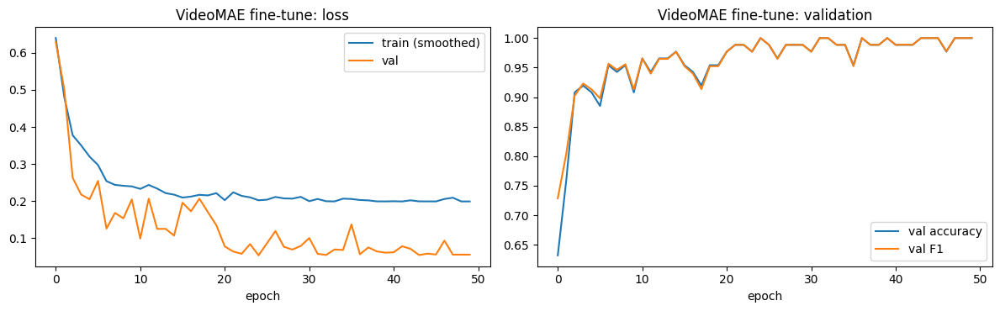

In [26]:
VM_CONFIG = dict(epochs=70, patience=25, lr=3e-5, head_lr=5e-4, weight_decay=0.05, warmup_epochs=1, label_smoothing=0.1, grad_clip=1.0)

seed_everything(SEED)
vm_groups = make_param_groups(vm_model, VM_CONFIG['lr'], VM_CONFIG['weight_decay'], head_keyword='classifier', head_lr=VM_CONFIG['head_lr'])
vm_model, vm_hist, vm_info = train_model(
    vm_model, vm_train_loader, vm_val_loader, vm_groups, VM_CONFIG['epochs'], VM_CONFIG['patience'], VM_AMP,
    accum=VM_ACCUM, warmup_epochs=VM_CONFIG['warmup_epochs'], label_smoothing=VM_CONFIG['label_smoothing'],
    grad_clip=VM_CONFIG['grad_clip'], tag='videomae')

VM_DIR = f'{SAVE_DIR}/videomae_shoplifting'
vm_model.m.save_pretrained(VM_DIR)
if vm_processor is not None:
    vm_processor.save_pretrained(VM_DIR)
plot_history(vm_hist, 'VideoMAE fine-tune', 'videomae_history.png')

predict:   0%|          | 0/12 [00:00<?, ?it/s]

predict:   0%|          | 0/47 [00:00<?, ?it/s]

best epoch: 25 | 65s per epoch
best val | acc 1.0000 | prec 1.0000 | rec 1.0000 | f1 1.0000

                     Eval  acc  precision  recall  f1  macro_f1  auc
 test, 1 view (16 frames)  1.0        1.0     1.0 1.0       1.0  1.0
test, 4 views (64 frames)  1.0        1.0     1.0 1.0       1.0  1.0

Week 5 reported F1: 0.9247

VideoMAE 1 view
              precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        45
 shoplifting     1.0000    1.0000    1.0000        49

    accuracy                         1.0000        94
   macro avg     1.0000    1.0000    1.0000        94
weighted avg     1.0000    1.0000    1.0000        94

VideoMAE 4 views
              precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        45
 shoplifting     1.0000    1.0000    1.0000        49

    accuracy                         1.0000        94
   macro avg     1.0000    1.0000    1.0000        94
weighted avg     1.0000    1.0000    1.

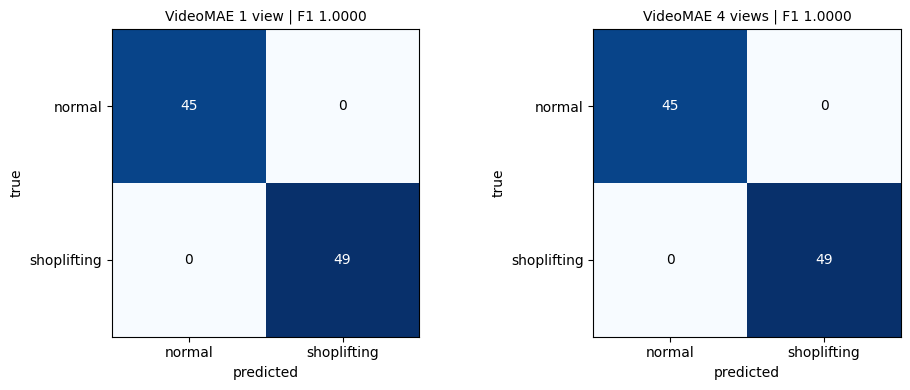

In [28]:
vm_test_loader = make_loader(ShopliftingDataset(test_df, vm_sets, False, eval_views=[CENTER_VIEW], **vm_aug), VM_BATCH * 2, False)
vm_test_multi_loader = make_loader(ShopliftingDataset(test_df, vm_sets, False, eval_views=list(range(N_VIEWS)), **vm_aug), max(1, VM_BATCH // 2), False)

vm_test_single = compute_metrics(*predict(vm_model, vm_test_loader, VM_AMP))
vm_test_multi = compute_metrics(*predict(vm_model, vm_test_multi_loader, VM_AMP))

print(f"best epoch: {vm_info['best_epoch']} | {vm_info['sec_per_epoch']:.0f}s per epoch")
print(f"best val | acc {vm_info['best_val']['acc']:.4f} | prec {vm_info['best_val']['precision']:.4f} | "
      f"rec {vm_info['best_val']['recall']:.4f} | f1 {vm_info['best_val']['f1']:.4f}")
print()

vm_only = pd.DataFrame([
    {'Eval': f'test, 1 view ({VM_FRAMES} frames)', **{k: vm_test_single[k] for k in ['acc', 'precision', 'recall', 'f1', 'macro_f1', 'auc']}},
    {'Eval': f'test, {N_VIEWS} views ({N_VIEWS * VM_FRAMES} frames)', **{k: vm_test_multi[k] for k in ['acc', 'precision', 'recall', 'f1', 'macro_f1', 'auc']}},
])
print(vm_only.round(4).to_string(index=False))
print()
print(f"Week 5 reported F1: {WEEK5_RESULT['f1']:.4f}")
print()

for name, r in [('1 view', vm_test_single), (f'{N_VIEWS} views', vm_test_multi)]:
    print(f'VideoMAE {name}')
    print(classification_report(r['labels'], r['preds'], target_names=['normal', 'shoplifting'], digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, r) in zip(axes, [('1 view', vm_test_single), (f'{N_VIEWS} views', vm_test_multi)]):
    cm = confusion_matrix(r['labels'], r['preds'], labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['normal', 'shoplifting'])
    ax.set_yticklabels(['normal', 'shoplifting'])
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(f"VideoMAE {name} | F1 {r['f1']:.4f}", fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/videomae_test_confusion.png', dpi=120, bbox_inches='tight')
plt.show()

## 12. Test results

- Single view = 16 frames (center view), same input budget as Week 5
- Multi view = average of 4 views, so 64 different frames of the video are seen
- I pick the final VideoMAE mode using **validation** F1, not test, to keep the test set honest

predict:   0%|          | 0/44 [00:00<?, ?it/s]

predict:   0%|          | 0/12 [00:00<?, ?it/s]

predict:   0%|          | 0/47 [00:00<?, ?it/s]

val F1 single 1.0000 | multi 1.0000 -> final mode: single

Scratch ResCNN-BiLSTM T=32
              precision    recall  f1-score   support

      normal     1.0000    0.9778    0.9888        45
 shoplifting     0.9800    1.0000    0.9899        49

    accuracy                         0.9894        94
   macro avg     0.9900    0.9889    0.9893        94
weighted avg     0.9896    0.9894    0.9894        94

VideoMAE 1 view
              precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        45
 shoplifting     1.0000    1.0000    1.0000        49

    accuracy                         1.0000        94
   macro avg     1.0000    1.0000    1.0000        94
weighted avg     1.0000    1.0000    1.0000        94

VideoMAE 4 views
              precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        45
 shoplifting     1.0000    1.0000    1.0000        49

    accuracy                         1.0000        94
   macro 

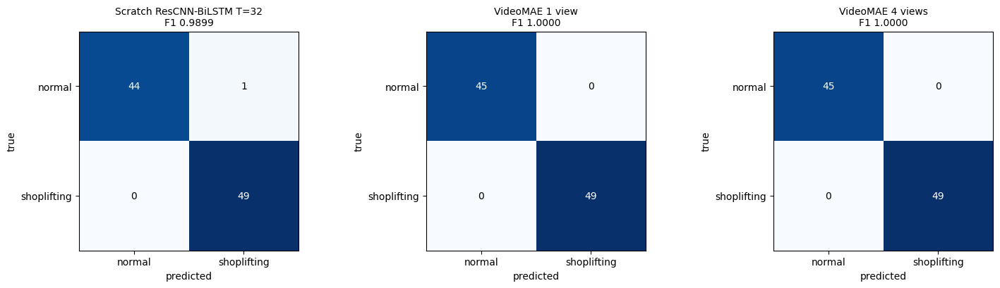

In [30]:
vm_val_multi_loader = make_loader(ShopliftingDataset(val_df, vm_sets, False, eval_views=list(range(N_VIEWS)), **vm_aug), max(1, VM_BATCH // 2), False)
vm_test_loader = make_loader(ShopliftingDataset(test_df, vm_sets, False, eval_views=[CENTER_VIEW], **vm_aug), VM_BATCH * 2, False)
vm_test_multi_loader = make_loader(ShopliftingDataset(test_df, vm_sets, False, eval_views=list(range(N_VIEWS)), **vm_aug), max(1, VM_BATCH // 2), False)

vm_val_single = vm_info['best_val']
vm_val_multi = compute_metrics(*predict(vm_model, vm_val_multi_loader, VM_AMP))
vm_test_single = compute_metrics(*predict(vm_model, vm_test_loader, VM_AMP))
vm_test_multi = compute_metrics(*predict(vm_model, vm_test_multi_loader, VM_AMP))
FINAL_VM_MODE = 'multi' if vm_val_multi['f1'] > vm_val_single['f1'] else 'single'
vm_final = vm_test_multi if FINAL_VM_MODE == 'multi' else vm_test_single
print(f"val F1 single {vm_val_single['f1']:.4f} | multi {vm_val_multi['f1']:.4f} -> final mode: {FINAL_VM_MODE}")
print()

results = {
    f'Scratch ResCNN-BiLSTM T={BEST_T}': scratch_test,
    'VideoMAE 1 view': vm_test_single,
    'VideoMAE 4 views': vm_test_multi,
}
for name, r in results.items():
    print(name)
    print(classification_report(r['labels'], r['preds'], target_names=['normal', 'shoplifting'], digits=4, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(r['labels'], r['preds'], labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['normal', 'shoplifting'])
    ax.set_yticklabels(['normal', 'shoplifting'])
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(f"{name}\nF1 {r['f1']:.4f}", fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
wrong = test_df.assign(true=vm_final['labels'], pred=vm_final['preds'], p_shoplifting=vm_final['probs'][:, 1])
wrong = wrong[wrong['true'] != wrong['pred']]
print(f'VideoMAE ({FINAL_VM_MODE}) mistakes on test: {len(wrong)} / {len(test_df)}')
print(wrong[['clip_id', 'class', 'p_shoplifting', 'duration', 'path']].round(3).to_string(index=False))

show_wrong = wrong.head(4)
if len(show_wrong):
    fig, axes = plt.subplots(len(show_wrong), 4, figsize=(12, 2.4 * len(show_wrong)), squeeze=False)
    for r, (_, row) in enumerate(show_wrong.iterrows()):
        arr = np.load(cache_path_for(int(row['clip_id'])), mmap_mode='r')
        for c, f in enumerate([4, 20, 36, 52]):
            axes[r, c].imshow(arr[f])
            axes[r, c].axis('off')
        axes[r, 0].set_title(f"#{row['clip_id']} true {IDX_TO_NAME[row['true']]}, p(shoplifting)={row['p_shoplifting']:.2f}", fontsize=8, loc='left')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/videomae_mistakes.png', dpi=100, bbox_inches='tight')
    plt.show()

## 13. Speed and size benchmark

- Inference time for **one video**, batch size 1, after warmup, same GPU for both models
- fp32 and mixed precision (AMP) on GPU, and fp32 on CPU (closer to a cheap edge device)
- VideoMAE 4 views = 4 clips per video, so it costs about 4 times the single view
- Size = the saved weights on disk
- Week 5 row: same architecture at T=16, so the speed is measured with a fresh model of that size

In [32]:
def file_mb(path):
    if os.path.isdir(path):
        return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs if f.endswith(('.safetensors', '.bin'))) / 1e6
    return os.path.getsize(path) / 1e6


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def peak_mem_mb(model, shape, amp_dtype=None):
    if device.type != 'cuda':
        return float('nan')
    free_memory()
    torch.cuda.reset_peak_memory_stats()
    ctx = torch.autocast(device_type='cuda', dtype=amp_dtype) if amp_dtype is not None else nullcontext()
    with torch.no_grad(), ctx:
        model(torch.randn(shape, device=device))
    torch.cuda.synchronize()
    return torch.cuda.max_memory_allocated() / 1e6


def benchmark(model, shape, amp_dtype, size_mb, cpu_runs):
    model = model.to(device).eval()
    gpu_ok = device.type == 'cuda'
    b = dict(params=count_params(model), size=size_mb)
    b['gpu_fp32'] = time_inference(model, shape, device) if gpu_ok else float('nan')
    b['gpu_amp'] = time_inference(model, shape, device, amp_dtype=amp_dtype) if gpu_ok else float('nan')
    b['peak_mb'] = peak_mem_mb(model, shape, amp_dtype)
    cpu_model = copy.deepcopy(model).cpu().float()
    b['cpu'] = time_inference(cpu_model, shape, torch.device('cpu'), runs=cpu_runs, warmup=1)
    del cpu_model
    free_memory()
    return b


bench = {}
bench_bar = tqdm(total=4, desc='benchmark')
week5_like = ResCNNLSTM().to(device)
bench['week5'] = benchmark(week5_like, (1, 16, 3, *SCRATCH_CROP), SCRATCH_AMP, WEEK5_RESULT['size_mb'], 10)
bench['week5']['params'] = WEEK5_RESULT['params']
bench_bar.update(1)
del week5_like
bench['scratch'] = benchmark(scratch_model, (1, BEST_T, 3, *SCRATCH_CROP), SCRATCH_AMP, file_mb(SCRATCH_PATH), 10)
bench_bar.update(1)
vm_size = file_mb(VM_DIR)
bench['vm_single'] = benchmark(vm_model, (1, VM_FRAMES, 3, *VM_CROP), VM_AMP, vm_size, 3)
bench_bar.update(1)
bench['vm_multi'] = benchmark(vm_model, (N_VIEWS, VM_FRAMES, 3, *VM_CROP), VM_AMP, vm_size, 2)
bench_bar.update(1)
bench_bar.close()
print(pd.DataFrame(bench).T.round(2).to_string())

benchmark:   0%|          | 0/4 [00:00<?, ?it/s]

               params    size  gpu_fp32  gpu_amp  peak_mb       cpu
week5       1622690.0    6.53      6.10     2.79   425.48    169.92
scratch     1622690.0    6.53     12.40     5.27   454.73    348.47
vm_single  86228738.0  344.94    120.09    29.33   603.47   3715.16
vm_multi   86228738.0  344.94    499.13   131.24   747.34  16117.17


## 14. Comparison table and trade-offs

In [ ]:
def table_row(name, met, b, sec_per_epoch, best_epoch, split):
    return {
        'Model': name, 'Split': split,
        'Accuracy': met['acc'], 'Precision': met['precision'], 'Recall': met['recall'], 'F1': met['f1'],
        'Macro F1': met['macro_f1'], 'ROC AUC': met.get('auc', float('nan')),
        'Params (M)': b['params'] / 1e6, 'Size (MB)': b['size'],
        'GPU ms/video fp32': b['gpu_fp32'], 'GPU ms/video AMP': b['gpu_amp'], 'CPU ms/video': b['cpu'],
        'Peak GPU MB': b['peak_mb'], 'Train s/epoch': sec_per_epoch, 'Best epoch': best_epoch,
    }

comparison = pd.DataFrame([
    table_row('Week 5 scratch ResCNN-BiLSTM T=16 (reported)', WEEK5_RESULT, bench['week5'],
              WEEK5_RESULT['sec_per_epoch'], WEEK5_RESULT['best_epoch'], 'old random split (leaky)'),
    table_row(f'Scratch ResCNN-BiLSTM T={BEST_T} (retrained)', scratch_test, bench['scratch'],
              scratch_info['sec_per_epoch'], scratch_info['best_epoch'], 'clean group split'),
    table_row('VideoMAE-B fine-tuned, 1 view', vm_test_single, bench['vm_single'],
              vm_info['sec_per_epoch'], vm_info['best_epoch'], 'clean group split'),
    table_row('VideoMAE-B fine-tuned, 4 views', vm_test_multi, bench['vm_multi'],
              vm_info['sec_per_epoch'], vm_info['best_epoch'], 'clean group split'),
])
comparison.to_csv(f'{SAVE_DIR}/comparison.csv', index=False)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
comparison.round(4)

In [ ]:
short = ['Week 5 (reported)', f'Scratch T={BEST_T}', 'VideoMAE 1 view', 'VideoMAE 4 views']
colors = ['#8C8C8C', '#4C72B0', '#DD8452', '#C44E52']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
panels = [('F1', 'Test F1 (higher is better)', False),
          ('GPU ms/video fp32', 'GPU ms per video (lower is better)', True),
          ('Size (MB)', 'Model size MB (lower is better)', True)]
for ax, (col, title, logy) in zip(axes, panels):
    vals = comparison[col].values
    ax.bar(short, vals, color=colors)
    ax.set_title(title)
    if logy:
        ax.set_yscale('log')
    else:
        ax.set_ylim(max(0, np.nanmin(vals) - 0.1), 1.0)
    for k, v in enumerate(vals):
        if not np.isnan(v):
            ax.text(k, v, f'{v:.3f}' if col == 'F1' else f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/comparison.png', dpi=120, bbox_inches='tight')
plt.show()

In [35]:
sc = comparison.iloc[1]
vm = comparison.iloc[3] if FINAL_VM_MODE == 'multi' else comparison.iloc[2]
vm1 = comparison.iloc[2]
print(f"final VideoMAE ({FINAL_VM_MODE} view) test F1: {vm['F1']:.4f}")
print(f"  vs Week 5 reported F1 {WEEK5_RESULT['f1']:.4f}: {vm['F1'] - WEEK5_RESULT['f1']:+.4f}")
print(f"  vs scratch on same clean split {sc['F1']:.4f}: {vm['F1'] - sc['F1']:+.4f}")
print()
print(f"VideoMAE has {vm1['Params (M)'] / sc['Params (M)']:.0f}x more parameters and a {vm1['Size (MB)'] / sc['Size (MB)']:.0f}x bigger file")
print(f"1 view is {vm1['GPU ms/video fp32'] / sc['GPU ms/video fp32']:.1f}x slower on GPU (fp32) and {vm1['CPU ms/video'] / sc['CPU ms/video']:.1f}x slower on CPU")
print(f"AMP makes VideoMAE {vm1['GPU ms/video fp32'] / vm1['GPU ms/video AMP']:.1f}x faster on GPU")
print(f"4 views cost {comparison.iloc[3]['GPU ms/video fp32'] / vm1['GPU ms/video fp32']:.1f}x the 1 view time for {comparison.iloc[3]['F1'] - vm1['F1']:+.4f} F1")
print(f"VideoMAE throughput on GPU with AMP: about {1000 / vm1['GPU ms/video AMP']:.0f} videos per second")
print(f"training: {vm1['Train s/epoch']:.0f}s per epoch, best at epoch {int(vm1['Best epoch'])} vs scratch {sc['Train s/epoch']:.0f}s per epoch, best at epoch {int(sc['Best epoch'])}")

final VideoMAE (single view) test F1: 1.0000
  vs Week 5 reported F1 0.9247: +0.0753
  vs scratch on same clean split 0.9899: +0.0101

VideoMAE has 53x more parameters and a 53x bigger file
1 view is 9.7x slower on GPU (fp32) and 10.7x slower on CPU
AMP makes VideoMAE 4.1x faster on GPU
4 views cost 4.2x the 1 view time for +0.0000 F1
VideoMAE throughput on GPU with AMP: about 34 videos per second
training: 65s per epoch, best at epoch 25 vs scratch 53s per epoch, best at epoch 70


### 14.1 Trade-offs discussion

**Accuracy**
- VideoMAE starts from features learned on Kinetics 400 (hundreds of thousands of human action videos), so it already understands hands, objects and body motion
- My scratch model has to learn everything from about 600 training videos, which is why it needs many more epochs and is less stable
- Retraining the scratch model on the clean split shows how much of the Week 5 score came from leakage. The pretrained model is compared on the same clean split, so the F1 gap is a fair one
- Multi-view helps when the theft happens in a short part of the video, because 64 frames are seen instead of 16

**Inference speed**
- The scratch model is tiny and runs fast even on CPU, so it fits real time CCTV on cheap hardware
- VideoMAE is much slower per video (attention over 1568 tokens), especially on CPU. On a GPU with AMP it is still fast enough for a few cameras
- Multi-view multiplies the cost by 4, so it makes sense only when accuracy matters more than latency

**Model size**
- About 6 MB vs about 350 MB. The scratch model can run on an edge device. VideoMAE needs a server GPU, or more work (fp16, quantization, distillation)

**Training cost**
- VideoMAE needs more GPU memory and time per epoch, but it converges in only a few epochs
- The scratch model is cheap per epoch but needs tens of epochs

**My conclusion**
- If accuracy matters most (security alerts, fewer missed thefts): fine-tuned VideoMAE
- If cost and speed matter most (many cameras on edge devices): the scratch model or a small pretrained model like X3D
- A good real setup: the small model screens all cameras and VideoMAE double checks only the suspicious clips

## 15. Saving the models

- Scratch weights: `.pt` state dict
- VideoMAE: `save_pretrained` folder (config + safetensors + processor), so it can be loaded with `from_pretrained`
- Results, split, duplicate report and figures are saved too, then everything is copied to Drive
- At the end I reload both saved models and check they give the same test predictions

In [36]:
meta = {
    'task': 'shoplifting detection, binary video classification',
    'classes': {str(k): v for k, v in IDX_TO_NAME.items()},
    'pretrained_model': MODEL_ID,
    'videomae': {
        'frames': VM_FRAMES, 'input_shape': ['batch', VM_FRAMES, 3, *VM_CROP], 'mean': VM_MEAN, 'std': VM_STD,
        'sampling': f'{N_CACHE} uniform frames per video, view k uses frames k, k+{N_VIEWS}, ... ; final mode {FINAL_VM_MODE}',
        'resize_hw': list(VM_RESIZE), 'center_crop_hw': list(VM_CROP), 'config': VM_CONFIG,
    },
    'scratch': {
        'frames': BEST_T, 'input_shape': ['batch', BEST_T, 3, *SCRATCH_CROP], 'input_range': '[0, 1] RGB',
        'resize_hw': list(SCRATCH_RESIZE), 'center_crop_hw': list(SCRATCH_CROP), 'config': SCRATCH_CONFIG,
    },
    'duplicates': {'app_thr': APP_THR, 'mot_thr': MOT_THR, **{k: int(v) for k, v in dup_summary.items()}},
    'split_sizes': {s: int((clean_df['split'] == s).sum()) for s in ['train', 'val', 'test']},
    'test_metrics': {row['Model']: {k: round(float(row[k]), 4) for k in ['Accuracy', 'Precision', 'Recall', 'F1']}
                     for _, row in comparison.iterrows()},
}
with open(f'{SAVE_DIR}/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

reloaded_vm = VideoMAEClassifier(VideoMAEForVideoClassification.from_pretrained(VM_DIR)).to(device)
p_reload = predict(reloaded_vm, vm_test_loader, VM_AMP)[0].numpy()
agree_vm = (p_reload.argmax(1) == vm_test_single['preds']).mean()
reloaded_sc = ResCNNLSTM().to(device)
reloaded_sc.load_state_dict(torch.load(SCRATCH_PATH, map_location=device))
p_reload_sc = predict(reloaded_sc, sc_test_loader, SCRATCH_AMP)[0].numpy()
agree_sc = (p_reload_sc.argmax(1) == scratch_test['preds']).mean()
print(f'reloaded VideoMAE agrees with test predictions: {agree_vm:.1%}')
print(f'reloaded scratch agrees with test predictions: {agree_sc:.1%}')
assert agree_vm > 0.99 and agree_sc > 0.99
del reloaded_vm, reloaded_sc
free_memory()

if IN_COLAB:
    shutil.copytree(SAVE_DIR, DRIVE_DIR, dirs_exist_ok=True)
    print('copied to', DRIVE_DIR)
for r, _, fs in os.walk(SAVE_DIR):
    for f in sorted(fs):
        p = os.path.join(r, f)
        print(f'{os.path.relpath(p, SAVE_DIR)}: {os.path.getsize(p) / 1e6:.2f} MB')

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

predict:   0%|          | 0/12 [00:00<?, ?it/s]

predict:   0%|          | 0/6 [00:00<?, ?it/s]

reloaded VideoMAE agrees with test predictions: 100.0%
reloaded scratch agrees with test predictions: 100.0%
copied to /content/drive/MyDrive/shop_pretrained
comparison.csv: 0.00 MB
duplicate_pairs.csv: 0.04 MB
meta.json: 0.00 MB
scratch_res_cnn_lstm_T32.pt: 6.53 MB
split.csv: 0.09 MB
t_ablation.csv: 0.00 MB
videomae_shoplifting/config.json: 0.00 MB
videomae_shoplifting/model.safetensors: 344.94 MB
videomae_shoplifting/preprocessor_config.json: 0.00 MB
figures/comparison.png: 0.06 MB
figures/confusion_matrices.png: 0.03 MB
figures/dup_below.png: 1.56 MB
figures/dup_border.png: 1.55 MB
figures/dup_top.png: 1.10 MB
figures/duplicate_similarity.png: 0.16 MB
figures/scratch_history.png: 0.08 MB
figures/t_ablation.png: 0.06 MB
figures/videomae_augmentation.png: 1.16 MB
figures/videomae_history.png: 0.06 MB
figures/videomae_test_confusion.png: 0.02 MB


### 15.1 Requirements check

In [ ]:
final_checks = {
    'pretrained video model loaded from Hugging Face without errors': len(load_info['error_msgs']) == 0,
    'classifier head adapted to 2 classes': vm_model.m.classifier.out_features == 2 and vm_model.m.config.num_labels == 2,
    'Week 5 frame sampling and augmentation reused': np.array_equal(vm_sets[CENTER_VIEW], get_frame_indices(N_CACHE, VM_FRAMES)),
    f"fine-tuned F1 ({vm_final['f1']:.4f}) > Week 5 scratch F1 ({WEEK5_RESULT['f1']:.4f})": vm_final['f1'] > WEEK5_RESULT['f1'],
    f"fine-tuned F1 ({vm_final['f1']:.4f}) > retrained scratch F1 on same split ({scratch_test['f1']:.4f})": vm_final['f1'] > scratch_test['f1'],
    'comparison table saved': os.path.exists(f'{SAVE_DIR}/comparison.csv'),
    'duplicate checks + leak free split done': os.path.exists(f'{SAVE_DIR}/split.csv'),
    'T analysis done': os.path.exists(f'{SAVE_DIR}/t_ablation.csv'),
    'models saved': os.path.exists(SCRATCH_PATH) and os.path.exists(f'{VM_DIR}/config.json'),
}
for k, v in final_checks.items():
    print('PASS' if v else 'FAIL', '|', k)

## 14. Comparison

### 14.1 Results on the test set

- Test set = 94 clips from the clean group split (45 normal, 49 shoplifting)
- Week 5 row is the number I reported last week on the old random split, so it is not on the same test clips

| Model | Split | Accuracy | Precision | Recall | F1 | Macro F1 |
|---|---|---|---|---|---|---|
| Week 5 scratch ResCNN-BiLSTM, T=16 (reported) | old random split (leaky) | 0.9457 | 0.9773 | 0.8776 | 0.9247 | 0.9412 |
| Scratch ResCNN-BiLSTM, T=32 (retrained) | clean group split | 0.9894 | 0.9800 | 1.0000 | 0.9899 | 0.9893 |
| VideoMAE-B fine-tuned, 1 view (16 frames) | clean group split | **1.0000** | **1.0000** | **1.0000** | **1.0000** | **1.0000** |
| VideoMAE-B fine-tuned, 4 views (64 frames) | clean group split | **1.0000** | **1.0000** | **1.0000** | **1.0000** | **1.0000** |

### 14.2 Size and speed

- Time is for 1 video, batch size 1, measured after warmup on the same Tesla T4
- CPU time is on the Colab CPU

| Model | Params | Size (MB) | GPU ms/video fp32 | GPU ms/video AMP | CPU ms/video | Peak GPU MB | Train s/epoch | Best epoch |
|---|---|---|---|---|---|---|---|---|
| Week 5 scratch, T=16 | 1.62M | 6.53 | 6.1 | 2.8 | 169.9 | 425 | 18 | 55 |
| Scratch, T=32 | 1.62M | 6.53 | 12.4 | 5.3 | 348.5 | 455 | 53 | 70 |
| VideoMAE, 1 view | 86.23M | 344.94 | 120.1 | 29.3 | 3715.2 | 603 | 65 | 25 |
| VideoMAE, 4 views | 86.23M | 344.94 | 499.1 | 131.2 | 16117.2 | 747 | 65 | 25 |

### 14.3 What the numbers say

**Accuracy**
- VideoMAE got F1 = 1.0 on test, higher than the Week 5 model (0.9247) and higher than the scratch model retrained on the same clean split (0.9899)
- The gap with the retrained scratch model is small: it made only 1 mistake out of 94 (1 normal clip predicted as shoplifting)
- Test set is small, so 1.0 does not mean the model is perfect, it means it got all 94 clips right
- 4 views gave the same F1 as 1 view here, so the extra frames did not help on this test set

**Training**
- VideoMAE learned very fast: val F1 was 0.90 at epoch 3 and reached 1.0 at epoch 25
- Scratch model was unstable for the first 40 epochs (val F1 kept jumping between 0 and 0.9) and was still improving at epoch 70
- So pretrained features from Kinetics 400 make training much faster and more stable

**Speed**
- VideoMAE 1 view is about 10x slower than the scratch model on GPU and about 11x slower on CPU
- AMP makes VideoMAE about 4x faster on GPU (120 ms to 29 ms), about 34 videos per second on a T4
- On CPU VideoMAE needs about 3.7 s per video (16 s with 4 views), too slow for real time on cheap hardware
- 4 views cost about 4x the time for no F1 gain here

**Size**
- VideoMAE has 53x more parameters and a 53x bigger file (345 MB vs 6.5 MB)
- Scratch model can run on an edge device, VideoMAE needs a GPU server

### 14.4 About the Week 5 score

- The duplicate check found 218 exact duplicate pairs (the `_1` files), 46 near duplicate pairs and 8 near duplicates with different labels
- 52 of the 129 Week 5 test clips (40.3%) had a duplicate in Week 5 train, and 2 had label conflicts
- So the Week 5 score was measured partly on clips the model had already seen
- After cleaning (631 clips) and a group split, both models are tested on the same clean clips, so the comparison in 14.1 is fair

### 14.5 T analysis (scratch model, validation)

| T | Gap between frames (s) | Val F1 | Val acc | Inference ms/clip | Train s/epoch |
|---|---|---|---|---|---|
| 8 | 1.62 | 0.8966 | 0.8966 | 4.3 | 11.5 |
| 16 | 0.81 | 0.8941 | 0.8966 | 6.1 | 31.9 |
| 32 | 0.41 | **0.9070** | **0.9080** | 11.7 | 61.0 |
| 48 | 0.27 | 0.8706 | 0.8736 | 17.4 | 92.0 |

- T = 32 was the best on validation, so I used it for the final scratch model
- T = 48 was worse, probably because the LSTM overfits with more frames and so few videos
- Differences between T = 8, 16 and 32 are small (about 1%), so T = 16 was not a bad choice, but T = 32 sees the video every 0.4 s instead of 0.8 s

### 14.6 Conclusion

- Best accuracy: fine-tuned VideoMAE (F1 = 1.0), fast and stable training
- Best speed and size: scratch model (6.5 MB, about 5 ms per video on GPU with AMP), still very good (F1 = 0.99)
- For a real store: the small scratch model checks all cameras in real time, and VideoMAE double checks only the clips it marks as suspicious

### 14.7 Requirements check

| Requirement | Result |
|---|---|
| Pretrained model loaded from Hugging Face without errors | done, no missing or unexpected keys, only classifier re-initialized |
| Classifier head adapted to 2 classes | done, `Linear(768, 2)` |
| Week 5 frame sampling and augmentation reused | done, same `get_frame_indices` and `augment_clip` |
| Fine-tuned F1 higher than Week 5 scratch model | done, 1.0000 vs 0.9247 (and vs 0.9899 retrained) |
| Comparison table | done, 14.1 and 14.2 |
| Models saved | done, `scratch_res_cnn_lstm_T32.pt` and `videomae_shoplifting/` on Drive |